# Modelado global del error de pronóstico (Etapa A)

Primeros modelos de Machine Learning reales de la consigna (`consigna/Consigna TP3.pdf`, Etapa A): el target sigue
siendo `error_temp_c = fcst_temp_c - obs_temp_c` (igual que `6_baselines_globales.ipynb`), pero acá se entrenan
modelos de verdad -no reglas fijas- sobre un set de features más amplio que el que usa hoy
`8_interpretabilidad.ipynb` (que todavía corre con dos modelos *placeholder* sin tuning ni validación cruzada,
hallazgo 7 de `revision-pipeline-error.md`).

Se comparan 5 familias de modelos -regresión lineal regularizada (Ridge/Lasso/ElasticNet), K-vecinos más cercanos,
árbol de decisión, Random Forest y Gradient Boosting-, cada una con su propio pipeline de preprocesamiento
(escalado donde corresponde + one-hot encoding de `bioma`) y validación cruzada temporal (`TimeSeriesSplit`) para
elegir hiperparámetros. Al final se seleccionan los 2 modelos finales que pide la consigna -uno que priorice
interpretabilidad, otro que priorice minimizar el error- y se guardan para que `8_interpretabilidad.ipynb` los use
en vez de los placeholders.

**Alcance**: sólo `temp_c`, igual que el resto del pipeline de corrección del error hasta acá (baselines,
`3_analisis_temporal.ipynb`). Las otras 3 variables (`rh_pct`, `dewpoint_c`, `windspeed_kmh`) no tienen todavía el
feature engineering ni el diagnóstico de estacionariedad/ACF que sí tiene `temp_c`, así que quedan fuera de esta
notebook.

**Nota**: esta notebook no se ejecutó al escribirla -el código queda listo para correr celda por celda a mano.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.experimental import enable_halving_search_cv  # habilita HalvingRandomSearchCV (API experimental)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV, HalvingRandomSearchCV
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo

PROCESSED = '../data/processed/'
OUT = '../data/out/modelado_global/'
MODELOS_DIR = '../data/processed/modelos/'

aplicar_estilo()
figuras = {}  # se exportan todas al final

## 1. Carga y armado de la matriz de features

Mismo patrón de carga que `8_interpretabilidad.ipynb`: `panel_features_error_temp_c.csv` (features de
`3_analisis_temporal.ipynb` -lags 6/24, rolling, dirección de viento, vecinas-) mergeado con columnas de
`dataset_modelado.csv`. `features` trae su propia versión de `error_temp_c` (con interpolación acotada, pensada
para el diagnóstico de estacionariedad/ACF, no para ser target -ver hallazgo 1 de `revision-pipeline-error.md`), así
que se dropea antes del merge para que la única fuente del target sea `dataset_modelado.csv`.

De `dataset_modelado.csv` se suman, además de lo que ya trae `8_interpretabilidad.ipynb`, tres grupos de columnas
que hoy no se usan como feature del error: la hora cíclica (`hora_sin`/`hora_cos`, la consigna la pide
explícitamente y ya está calculada desde `3_analisis_temporal.ipynb`), un subconjunto de los atributos geográficos
de `4_atributos_geograficos.ipynb` (elevación y distancias), y el pronóstico mismo (`fcst_temp_c`, `fcst_pop_pct`)
-el sesgo de corrección suele depender también del valor pronosticado, no sólo de la dinámica pasada del error.

In [2]:
VARIABLE_OBJETIVO = 'temp_c'
COL_ERROR = f'error_{VARIABLE_OBJETIVO}'

features = pd.read_csv(PROCESSED + 'panel_features_error_temp_c.csv', parse_dates=['target_hour_utc'])
features = features.drop(columns=COL_ERROR)

cols_modelado = ['station_id', 'target_hour_utc', COL_ERROR, f'abs_{COL_ERROR}', f'target_valido_{VARIABLE_OBJETIVO}',
                  'hora_local', 'hora_sin', 'hora_cos', 'elevation',
                  'dist_agua_km', 'dist_aeropuerto_km', 'dist_area_urbana_km', 'area_urbana_km2',
                  'sobre_agua', 'en_area_urbana', 'bioma', 'fcst_temp_c', 'fcst_pop_pct', 'split']
modelado = pd.read_csv(PROCESSED + 'dataset_modelado.csv', usecols=cols_modelado, parse_dates=['target_hour_utc'])

assert not features.duplicated(['station_id', 'target_hour_utc']).any(), 'panel_features_error_temp_c tiene pares estación+hora repetidos'
assert not modelado.duplicated(['station_id', 'target_hour_utc']).any(), 'dataset_modelado tiene pares estación+hora repetidos'

datos = features.merge(modelado, on=['station_id', 'target_hour_utc'])
datos[['sobre_agua', 'en_area_urbana']] = datos[['sobre_agua', 'en_area_urbana']].astype(int)

print(f'{len(datos):,} filas tras el merge')

165,184 filas tras el merge


### Grupos de features

- **Numéricas continuas**: dinámica del error (`error_temp_c_lag6`, `error_temp_c_lag24`,
  `error_temp_c_roll3_mean`), espacial (`error_temp_c_vecinas_lag6_mean`), viento cíclico
  (`obs_wind_direction_sin/cos_lag6`), variables de sensores a horizonte (`obs_rh_pct_lag6`,
  `obs_dewpoint_c_lag6`, `obs_windspeed_kmh_lag6`), hora cíclica (`hora_sin`/`hora_cos`), geográficas
  (`elevation`, `dist_agua_km`, `dist_aeropuerto_km`, `dist_area_urbana_km`, `area_urbana_km2` -se usa `dist_agua_km`
  sola en vez de separar costa/lago porque están correlacionadas entre sí; `area_urbana_km2` no tiene faltantes,
  está definida tanto para estaciones dentro como fuera de área urbana) y **el pronóstico mismo**
  (`fcst_temp_c`, `fcst_pop_pct` -el sesgo de corrección suele depender del valor pronosticado en sí, no sólo de
  la dinámica del error). El faltante de `fcst_temp_c`/`fcst_pop_pct` (~26%) no cuesta filas nuevas: coincide casi
  exactamente con las filas que ya quedaban fuera por `target_valido_temp_c`.

  **`obs_dewpoint_c_lag6` y `obs_windspeed_kmh_lag6` (auditoría de la notebook, punto 2)**: la CCF del hallazgo 6
  (`3_analisis_temporal.ipynb`) no había encontrado correlación **lineal** de estas dos contra `error_temp_c`, pero
  esa prueba no descarta que un modelo de árbol capture una interacción no lineal (p. ej. humedad alta + viento
  nulo) -el mismo mecanismo que ya se confirmó con `fcst_temp_c`/`fcst_pop_pct`, que la CCF tampoco habría elegido
  y terminaron aportándole a Random Forest. Se agregan al set compartido: los modelos lineales, vía su propia
  regularización (Ridge/Lasso/ElasticNet), las van a descartar solas si no aportan -ya pasó con `fcst_*`-, así que
  no hace falta un set de features separado por familia de modelo.
- **Binarias (ya 0/1)**: `sobre_agua`, `en_area_urbana` -no necesitan encoding.
- **Categórica → one-hot encoding**: `bioma` (5 valores). `estado` (15) y `red` (19) quedan afuera por cardinalidad
  alta y porque `red` es un artefacto de la fuente de datos, no una variable geofísica; `categoria`
  (ok/intermitente) también queda afuera -es un flag de calidad de datos, no un predictor.

La presión atmosférica, que la consigna menciona como ejemplo, no está disponible en ningún archivo del
pipeline -no es una omisión de esta notebook, la fuente de datos del TP1 no la trae.

In [3]:
FEATURES_NUMERICAS = [
    'error_temp_c_lag6', 'error_temp_c_lag24', 'error_temp_c_roll3_mean',
    'error_temp_c_vecinas_lag6_mean',
    'obs_wind_direction_sin_lag6', 'obs_wind_direction_cos_lag6',
    'obs_rh_pct_lag6', 'obs_dewpoint_c_lag6', 'obs_windspeed_kmh_lag6',
    'hora_sin', 'hora_cos',
    'elevation', 'dist_agua_km', 'dist_aeropuerto_km', 'dist_area_urbana_km', 'area_urbana_km2',
    'fcst_temp_c', 'fcst_pop_pct',
]
FEATURES_BINARIAS = ['sobre_agua', 'en_area_urbana']
FEATURES_CATEGORICAS = ['bioma']
FEATURES = FEATURES_NUMERICAS + FEATURES_BINARIAS + FEATURES_CATEGORICAS

mascara = datos[f'target_valido_{VARIABLE_OBJETIVO}'] & datos[FEATURES].notna().all(axis=1)
datos_modelo = datos[mascara].copy().sort_values('target_hour_utc').reset_index(drop=True)

print(f'{len(datos_modelo):,} de {len(datos):,} filas entran al modelo ({100 * mascara.mean():.1f}%)')
print(f'Features: {FEATURES}')

X_train = datos_modelo.loc[datos_modelo['split'] == 'train', FEATURES]
y_train = datos_modelo.loc[datos_modelo['split'] == 'train', COL_ERROR]
X_test = datos_modelo.loc[datos_modelo['split'] == 'test', FEATURES]
y_test = datos_modelo.loc[datos_modelo['split'] == 'test', COL_ERROR]

assert datos_modelo.loc[X_train.index, 'target_hour_utc'].is_monotonic_increasing, \
    'X_train debe quedar ordenado cronológicamente: TimeSeriesSplit asume eso, no mira target_hour_utc'

print(f'train: {len(X_train):,} filas | test: {len(X_test):,} filas')

110,303 de 165,184 filas entran al modelo (66.8%)
Features: ['error_temp_c_lag6', 'error_temp_c_lag24', 'error_temp_c_roll3_mean', 'error_temp_c_vecinas_lag6_mean', 'obs_wind_direction_sin_lag6', 'obs_wind_direction_cos_lag6', 'obs_rh_pct_lag6', 'obs_dewpoint_c_lag6', 'obs_windspeed_kmh_lag6', 'hora_sin', 'hora_cos', 'elevation', 'dist_agua_km', 'dist_aeropuerto_km', 'dist_area_urbana_km', 'area_urbana_km2', 'fcst_temp_c', 'fcst_pop_pct', 'sobre_agua', 'en_area_urbana', 'bioma']
train: 82,950 filas | test: 27,353 filas


## 2. Preprocesamiento: escalado + one-hot encoding

Dos `ColumnTransformer` reusables, uno por tipo de modelo:

- `preprocesador_escalado`: `StandardScaler` en numéricas/binarias + one-hot en `bioma` -para los modelos que son
  sensibles a la escala (regresión lineal regularizada, KNN).
- `preprocesador_arboles`: numéricas/binarias sin tocar (`passthrough`) + el mismo one-hot en `bioma` -los modelos
  de árbol no necesitan escalado, pero sí one-hot para la categórica (no hay orden natural entre biomas).

Cada modelo se arma como `Pipeline([('prep', ...), ('modelo', ...)])`: así `GridSearchCV`/`RandomizedSearchCV`
ajusta el `StandardScaler`/`OneHotEncoder` sólo con los folds de train de cada partición de la validación cruzada,
sin fuga de información del fold de validación.

In [4]:
preprocesador_escalado = ColumnTransformer([
    ('num', StandardScaler(), FEATURES_NUMERICAS + FEATURES_BINARIAS),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), FEATURES_CATEGORICAS),
])

preprocesador_arboles = ColumnTransformer([
    ('num', 'passthrough', FEATURES_NUMERICAS + FEATURES_BINARIAS),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), FEATURES_CATEGORICAS),
])


## 3. Validación cruzada temporal

`TimeSeriesSplit(n_splits=5)` sobre `X_train` -ya ordenado por `target_hour_utc`-: cada fold de validación usa sólo
datos posteriores a su fold de entrenamiento, pooleando todas las estaciones (mismo criterio temporal que ya usó
`5_separacion_train_test.ipynb` para el corte único train/test). No es un K-fold al azar: evita que una fila de
validación quede "filtrada" por una fila de entrenamiento casi contigua en el tiempo, igual que se decidió para el
split train/test.

`evaluar_modelo` corre la búsqueda de hiperparámetros con esa validación cruzada, reentrena automáticamente el
mejor (`refit=True`, default de todas las `*SearchCV`) sobre **todo** train, y devuelve métricas sobre train y test
más el pipeline ya entrenado. Tres modos: `'grid'` (`GridSearchCV`, para grids chicos), `'random'`
(`RandomizedSearchCV`) y `'halving'` (`HalvingRandomSearchCV`, para Random Forest y Gradient Boosting -auditoría de
la notebook, punto 5). En `'halving'`, `resource` es el hiperparámetro que la búsqueda usa como "presupuesto"
creciente: arranca muchas combinaciones con pocos árboles/iteraciones (`min_resources`) y va invirtiendo más
recursos sólo en las combinaciones que van quedando mejor paradas, hasta `max_resources` -más eficiente que
`RandomizedSearchCV` para explorar rangos más anchos con el mismo presupuesto de cómputo.

In [5]:
cv_temporal = TimeSeriesSplit(n_splits=5)


def evaluar_modelo(nombre, pipeline, param_grid, metodo='grid', n_iter=20, random_state=0,
                    resource='n_samples', min_resources='exhaust', max_resources='auto', factor=3):
    """Busca hiperparametros con validacion cruzada temporal sobre train, reentrena el mejor sobre todo
    train y devuelve metricas train/test + el pipeline final ya entrenado."""
    if metodo == 'grid':
        buscador = GridSearchCV(pipeline, param_grid, cv=cv_temporal, scoring='neg_mean_absolute_error', n_jobs=-1)
    elif metodo == 'random':
        buscador = RandomizedSearchCV(pipeline, param_grid, n_iter=n_iter, cv=cv_temporal,
                                       scoring='neg_mean_absolute_error', n_jobs=-1, random_state=random_state)
    else:  # 'halving'
        buscador = HalvingRandomSearchCV(pipeline, param_grid, resource=resource, min_resources=min_resources,
                                          max_resources=max_resources, factor=factor, cv=cv_temporal,
                                          scoring='neg_mean_absolute_error', n_jobs=-1, random_state=random_state)
    buscador.fit(X_train, y_train)
    modelo_final = buscador.best_estimator_

    pred_train = modelo_final.predict(X_train)
    pred_test = modelo_final.predict(X_test)

    return {
        'nombre': nombre,
        'mejores_parametros': buscador.best_params_,
        'cv_MAE': -buscador.best_score_,
        'MAE_train': mean_absolute_error(y_train, pred_train),
        'RMSE_train': np.sqrt(mean_squared_error(y_train, pred_train)),
        'MAE_test': mean_absolute_error(y_test, pred_test),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, pred_test)),
        'modelo': modelo_final,
    }


resultados_modelos = {}  # nombre -> dict devuelto por evaluar_modelo, se completa en las secciones siguientes

## 4. Modelo 1 — Regresión lineal regularizada

Candidato principal para el entregable "interpretable": coeficientes directamente legibles (sobre todo con
features estandarizadas, donde la magnitud del coeficiente ya es comparable entre variables). Se prueban las 3
variantes clásicas -Ridge (L2), Lasso (L1, hace selección de variables llevando coeficientes a cero) y ElasticNet
(combinación de ambas)- y se compara cuál generaliza mejor.

In [6]:
pipeline_ridge = Pipeline([('prep', preprocesador_escalado), ('modelo', Ridge())])
grid_ridge = {'modelo__alpha': [0.01, 0.1, 1, 10, 100, 300, 1000]}  # ensanchado: 100 habia ganado en el borde

resultados_modelos['ridge'] = evaluar_modelo('ridge', pipeline_ridge, grid_ridge, metodo='grid')
print(f"Ridge - mejor alpha: {resultados_modelos['ridge']['mejores_parametros']}, "
      f"MAE test: {resultados_modelos['ridge']['MAE_test']:.3f}")

Ridge - mejor alpha: {'modelo__alpha': 1000}, MAE test: 1.173


In [7]:
pipeline_lasso = Pipeline([('prep', preprocesador_escalado), ('modelo', Lasso(max_iter=10000))])
grid_lasso = {'modelo__alpha': [0.001, 0.01, 0.1, 1, 10]}

resultados_modelos['lasso'] = evaluar_modelo('lasso', pipeline_lasso, grid_lasso, metodo='grid')
print(f"Lasso - mejor alpha: {resultados_modelos['lasso']['mejores_parametros']}, "
      f"MAE test: {resultados_modelos['lasso']['MAE_test']:.3f}")


Lasso - mejor alpha: {'modelo__alpha': 0.1}, MAE test: 1.154


In [8]:
pipeline_elastic = Pipeline([('prep', preprocesador_escalado), ('modelo', ElasticNet(max_iter=10000))])
grid_elastic = {'modelo__alpha': [0.001, 0.01, 0.1, 1, 10], 'modelo__l1_ratio': [0.1, 0.5, 0.9]}

resultados_modelos['elastic_net'] = evaluar_modelo('elastic_net', pipeline_elastic, grid_elastic, metodo='grid')
print(f"ElasticNet - mejores parámetros: {resultados_modelos['elastic_net']['mejores_parametros']}, "
      f"MAE test: {resultados_modelos['elastic_net']['MAE_test']:.3f}")


ElasticNet - mejores parámetros: {'modelo__alpha': 0.1, 'modelo__l1_ratio': 0.9}, MAE test: 1.154


In [9]:
mejor_lineal = min(['ridge', 'lasso', 'elastic_net'], key=lambda n: resultados_modelos[n]['MAE_test'])
modelo_lineal_final = resultados_modelos[mejor_lineal]['modelo']

nombres_features_ohe = modelo_lineal_final.named_steps['prep'].get_feature_names_out()
coeficientes = pd.Series(modelo_lineal_final.named_steps['modelo'].coef_, index=nombres_features_ohe,
                          name='coeficiente').sort_values(key=np.abs, ascending=False)
print(f'Mejor regresión lineal regularizada: {mejor_lineal}')
coeficientes


Mejor regresión lineal regularizada: elastic_net


num__error_temp_c_lag24                       0.659393
num__hora_sin                                -0.284210
num__error_temp_c_lag6                        0.258448
num__hora_cos                                 0.142078
num__obs_rh_pct_lag6                         -0.038359
num__obs_wind_direction_sin_lag6             -0.000000
num__error_temp_c_vecinas_lag6_mean           0.000000
num__error_temp_c_roll3_mean                  0.000000
num__obs_dewpoint_c_lag6                      0.000000
num__obs_wind_direction_cos_lag6              0.000000
num__obs_windspeed_kmh_lag6                  -0.000000
num__elevation                               -0.000000
num__dist_agua_km                            -0.000000
num__dist_aeropuerto_km                      -0.000000
num__dist_area_urbana_km                     -0.000000
num__area_urbana_km2                          0.000000
num__fcst_temp_c                              0.000000
num__fcst_pop_pct                             0.000000
num__sobre

## 5. Modelo 2 — K-vecinos más cercanos (KNN)

No es un candidato natural para ninguno de los dos entregables (no da coeficientes ni feature importance directa,
y no suele minimizar mejor que un ensamble de árboles) -se incluye como punto de comparación no paramétrico, para
confirmar que los modelos de árbol realmente aportan algo sobre un vecino-más-cercano simple.

**Costo computacional**: KNN es *lazy* -la búsqueda de vecinos se hace en cada `predict()`-, y con ~80-130 mil
filas de train cada combinación del grid puede tardar bastante (la validación cruzada corre el fit+predict 5 veces
por combinación). Si tarda demasiado al ejecutar, achicar `grid_knn` o cambiar a `RandomizedSearchCV`.

El grid se ensanchó (auditoría de la notebook, punto 5): la corrida anterior eligió `n_neighbors=100`, justo en el
borde superior del rango probado.

In [10]:
pipeline_knn = Pipeline([('prep', preprocesador_escalado), ('modelo', KNeighborsRegressor(n_jobs=-1))])
grid_knn = {'modelo__n_neighbors': [5, 10, 20, 50, 100, 150, 200], 'modelo__weights': ['uniform', 'distance']}

resultados_modelos['knn'] = evaluar_modelo('knn', pipeline_knn, grid_knn, metodo='grid')
print(f"KNN - mejores parámetros: {resultados_modelos['knn']['mejores_parametros']}, "
      f"MAE test: {resultados_modelos['knn']['MAE_test']:.3f}")

KNN - mejores parámetros: {'modelo__n_neighbors': 100, 'modelo__weights': 'distance'}, MAE test: 1.148


## 6. Modelo 3 — Árbol de decisión

Segundo candidato para el entregable "interpretable": con `max_depth` acotado, un árbol se puede dibujar y leer
como una serie de reglas -una interpretabilidad distinta a la de los coeficientes de la regresión lineal, más útil
si la relación entre features y error no es lineal (p. ej. umbrales de hora del día).

In [11]:
pipeline_arbol = Pipeline([('prep', preprocesador_arboles), ('modelo', DecisionTreeRegressor(random_state=0))])
grid_arbol = {'modelo__max_depth': [3, 5, 8, 12, None], 'modelo__min_samples_leaf': [1, 5, 20, 50]}

resultados_modelos['arbol'] = evaluar_modelo('arbol', pipeline_arbol, grid_arbol, metodo='grid')
print(f"Árbol de decisión - mejores parámetros: {resultados_modelos['arbol']['mejores_parametros']}, "
      f"MAE test: {resultados_modelos['arbol']['MAE_test']:.3f}")


Árbol de decisión - mejores parámetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 50}, MAE test: 1.135


## 7. Modelo 4 — Random Forest

Candidato principal para "mínimo error": ensamble de árboles, robusto a outliers y a la escala de las features, sin
necesidad de asumir relaciones lineales.

**Auditoría de la notebook, punto 5**: la corrida anterior (`RandomizedSearchCV`) eligió `n_estimators=300` y
`max_depth=16`, los dos en el borde superior de sus rangos -señal de que el grid se quedó corto-. Se pasa a
`HalvingRandomSearchCV` usando `n_estimators` como *recurso*: en vez de fijar un puñado de valores de
`n_estimators` a probar, la búsqueda arranca muchas combinaciones de `max_depth`/`min_samples_leaf`/`max_features`
con pocos árboles (`min_resources=50`) y va invirtiendo más árboles -hasta `max_resources=500`- sólo en las
combinaciones más prometedoras. Permite explorar un rango de `n_estimators` mucho más amplio con el mismo
presupuesto de cómputo que antes.

In [12]:
pipeline_rf = Pipeline([('prep', preprocesador_arboles), ('modelo', RandomForestRegressor(random_state=0, n_jobs=-1))])
grid_rf = {
    'modelo__max_depth': [None, 8, 16, 24, 32],
    'modelo__min_samples_leaf': [1, 5, 10, 20, 50],
    'modelo__max_features': ['sqrt', 'log2', 0.3, 0.5, 0.7],
}

resultados_modelos['random_forest'] = evaluar_modelo(
    'random_forest', pipeline_rf, grid_rf, metodo='halving',
    resource='modelo__n_estimators', min_resources=50, max_resources=500, factor=3)
print(f"Random Forest - mejores parámetros: {resultados_modelos['random_forest']['mejores_parametros']}, "
      f"MAE test: {resultados_modelos['random_forest']['MAE_test']:.3f}")

Random Forest - mejores parámetros: {'modelo__min_samples_leaf': 5, 'modelo__max_features': 0.3, 'modelo__max_depth': 32, 'modelo__n_estimators': 450}, MAE test: 1.067


## 8. Modelo 5 — Gradient Boosting

Segundo candidato para "mínimo error": boosting en vez de bagging, suele superar a Random Forest en datasets
tabulares de este tamaño. Se usa `HistGradientBoostingRegressor` (nativo de scikit-learn, no hace falta instalar
XGBoost/LightGBM) -está optimizado para datasets grandes y es bastante más rápido que
`GradientBoostingRegressor` clásico con ~100 mil filas.

**Auditoría de la notebook, punto 5**: acá los 4 hiperparámetros de la corrida anterior quedaron en el borde de su
rango (`max_iter=300`, `learning_rate=0.01`, `max_depth=8`, `l2_regularization=0.0`) -la señal más clara de las
cinco familias de que el grid se había quedado corto. `learning_rate` bajo + `max_iter` alto es un patrón conocido
(tasas de aprendizaje chicas necesitan más iteraciones para converger), así que acá tiene especial sentido usar
`HalvingRandomSearchCV` con `max_iter` como recurso -el resto de los hiperparámetros se buscan con el `learning_rate`
ya ensanchado hacia abajo y `max_depth` hacia arriba; `l2_regularization=0.0` no se ensancha más abajo porque 0 ya
es el mínimo válido, no un límite artificial del grid.

In [13]:
pipeline_gb = Pipeline([('prep', preprocesador_arboles), ('modelo', HistGradientBoostingRegressor(random_state=0))])
grid_gb = {
    'modelo__learning_rate': [0.005, 0.01, 0.03, 0.05, 0.1],
    'modelo__max_depth': [None, 3, 5, 8, 12],
    'modelo__l2_regularization': [0.0, 0.1, 0.5, 1.0],
}

resultados_modelos['gradient_boosting'] = evaluar_modelo(
    'gradient_boosting', pipeline_gb, grid_gb, metodo='halving',
    resource='modelo__max_iter', min_resources=50, max_resources=1000, factor=3)
print(f"Gradient Boosting - mejores parámetros: {resultados_modelos['gradient_boosting']['mejores_parametros']}, "
      f"MAE test: {resultados_modelos['gradient_boosting']['MAE_test']:.3f}")

Gradient Boosting - mejores parámetros: {'modelo__max_depth': 8, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 0.0, 'modelo__max_iter': 450}, MAE test: 1.069


## 9. Comparación global

Se arma una tabla única con los 5 modelos entrenados acá más los dos puntos de referencia de
`6_baselines_globales.ipynb` (`cero` = no corregir nada, y el mejor de los 4 baselines simples,
`naive_estacional`). La consigna pide comparar el error del pronóstico original contra el del pronóstico corregido:
`MAE_test` de cada modelo acá es exactamente eso -el MAE del residuo (`error_real - error_predicho`) equivale al
MAE de `(fcst + corrección) - obs`, así que no hace falta una cuenta aparte.

In [ ]:
BASELINES_NOTEBOOK_6 = {
    "cero (no corregir)": 1.241,
    "naive_estacional (mejor baseline)": 1.499,
}

tabla_comparacion = pd.DataFrame([
    {"modelo": r["nombre"], "MAE_train": r["MAE_train"], "RMSE_train": r["RMSE_train"],
     "MAE_test": r["MAE_test"], "RMSE_test": r["RMSE_test"], "cv_MAE": r["cv_MAE"],
     "mejores_parametros": r["mejores_parametros"]}
    for r in resultados_modelos.values()
]).set_index("modelo")

for nombre, mae in BASELINES_NOTEBOOK_6.items():
    tabla_comparacion.loc[nombre, "MAE_test"] = mae

tabla_comparacion["mejora_vs_cero_pct"] = 100 * (1 - tabla_comparacion["MAE_test"] / BASELINES_NOTEBOOK_6["cero (no corregir)"])
tabla_comparacion.round(3).sort_values("MAE_test")


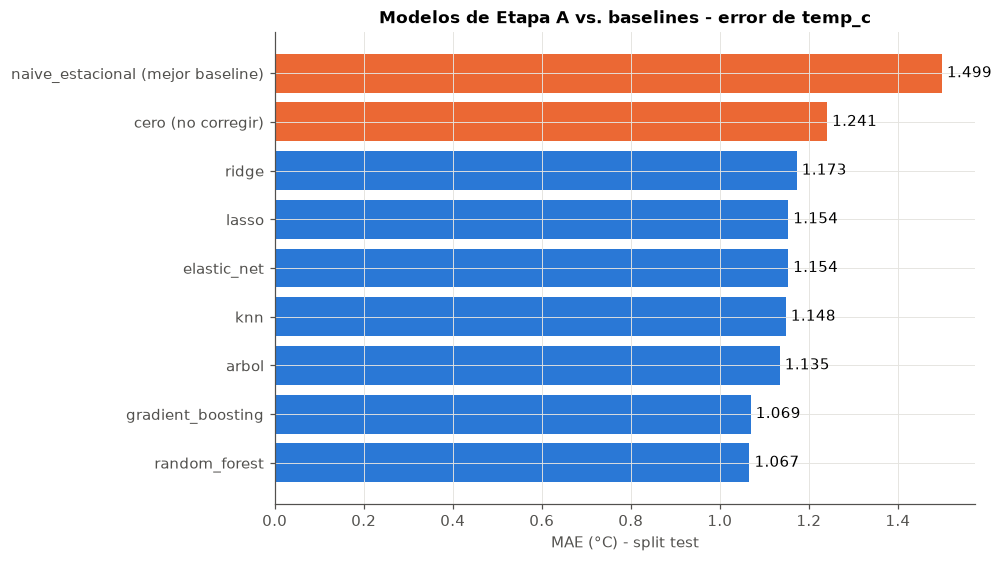

In [15]:
mae_test_ordenado = tabla_comparacion['MAE_test'].sort_values()

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
colores = [NARANJA if ('no corregir' in m or 'baseline' in m) else AZUL for m in mae_test_ordenado.index]
ax.barh(mae_test_ordenado.index, mae_test_ordenado.values, color=colores)
ax.set(xlabel='MAE (°C) - split test', title='Modelos de Etapa A vs. baselines - error de temp_c')
for y, v in enumerate(mae_test_ordenado.values):
    ax.text(v, y, f' {v:.3f}', va='center')
figuras['01_comparacion_modelos_mae_test'] = fig
plt.show()


## 10. Selección de los 2 modelos finales

Criterio explícito (y editable a mano si hace falta): **"mínimo error"** = el mejor `MAE_test` entre los 5 modelos
entrenados acá; **"interpretable"** = el mejor `MAE_test` entre los candidatos interpretables (las 3 variantes de
regresión lineal regularizada + el árbol de decisión).

Si al ver los números el criterio cualitativo de interpretabilidad pesa más que una diferencia chica de MAE -por
ejemplo, Ridge con coeficientes claros contra un árbol más profundo y más difícil de leer, aunque el árbol gane por
poco-, pisar `nombre_interpretable` a mano antes de correr la celda de guardado.

In [16]:
CANDIDATOS_INTERPRETABLES = ['ridge', 'lasso', 'elastic_net', 'arbol']

nombre_min_error = min(resultados_modelos, key=lambda n: resultados_modelos[n]['MAE_test'])
nombre_interpretable = min(CANDIDATOS_INTERPRETABLES, key=lambda n: resultados_modelos[n]['MAE_test'])

modelo_min_error_final = resultados_modelos[nombre_min_error]['modelo']
modelo_interpretable_final = resultados_modelos[nombre_interpretable]['modelo']

print(f'Modelo elegido como "mínimo error" (entregable 2): {nombre_min_error} '
      f'(MAE test = {resultados_modelos[nombre_min_error]["MAE_test"]:.3f})')
print(f'Modelo elegido como "interpretable" (entregable 1): {nombre_interpretable} '
      f'(MAE test = {resultados_modelos[nombre_interpretable]["MAE_test"]:.3f})')


Modelo elegido como "mínimo error" (entregable 2): random_forest (MAE test = 1.067)
Modelo elegido como "interpretable" (entregable 1): arbol (MAE test = 1.135)


## 11. Guardado

Se guardan los dos pipelines finales ya entrenados (preprocesamiento + modelo, con `joblib`) para que
`8_interpretabilidad.ipynb` los cargue directamente en vez de entrenar los placeholders -deja preparado el
hallazgo 7 de `revision-pipeline-error.md`-, más la tabla de comparación y el gráfico.

In [17]:
os.makedirs(MODELOS_DIR, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

joblib.dump(modelo_interpretable_final, MODELOS_DIR + f'modelo_interpretable_{VARIABLE_OBJETIVO}.joblib')
joblib.dump(modelo_min_error_final, MODELOS_DIR + f'modelo_min_error_{VARIABLE_OBJETIVO}.joblib')

for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_comparacion.round(3).to_csv(OUT + f'tabla_comparacion_modelos_{VARIABLE_OBJETIVO}.csv')

print(f'Modelos finales guardados en {MODELOS_DIR}')
print(f'Guardados {len(figuras)} gráfico(s) y 1 tabla en {OUT}')


Modelos finales guardados en ../data/processed/modelos/
Guardados 1 gráfico(s) y 1 tabla en ../data/out/modelado_global/
